In [1]:
# 01. Data Loading & Validation

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customer_churn_data.csv")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

df.head()

Dataset shape: (70, 10)

Missing values:
user_id              0
age                  0
country              0
subscription_type    0
device               0
daily_minutes        0
favorite_genre       0
skip_rate            2
ads_clicked          0
churned              0
dtype: int64


,user_id,age,country,subscription_type,device,daily_minutes,favorite_genre,skip_rate,ads_clicked,churned
0,U001,22,TR,free,mobile,45,pop,0.35,1,0
1,U002,30,DE,premium,desktop,120,rock,0.10,0,0
2,U003,27,TR,free,mobile,30,hiphop,0.50,1,1
3,U004,35,UK,premium,desktop,150,jazz,0.05,0,0
4,U005,19,TR,free,mobile,25,pop,0.60,1,1


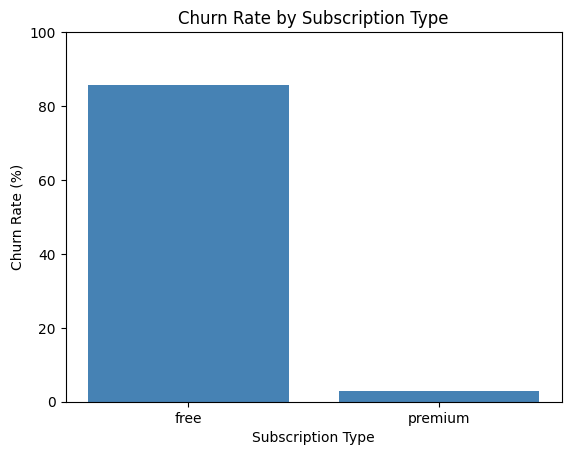

In [3]:
# 02. Churn by Subscription Type

subscription_churn = df.groupby("subscription_type")["churned"].mean() * 100

plt.bar(subscription_churn.index, subscription_churn.values, color="steelblue")
plt.title("Churn Rate by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.show()

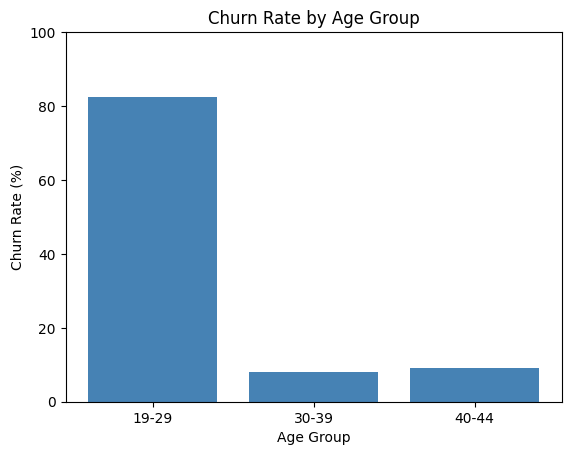

In [4]:
# 03. Churn by Age Group

df["age_group"] = pd.cut(
    df["age"],
    bins=[18, 29, 39, 44],
    labels=["19-29", "30-39", "40-44"]
)

age_churn = df.groupby("age_group", observed=True)["churned"].mean() * 100

plt.bar(age_churn.index, age_churn.values, color="steelblue")
plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.show()

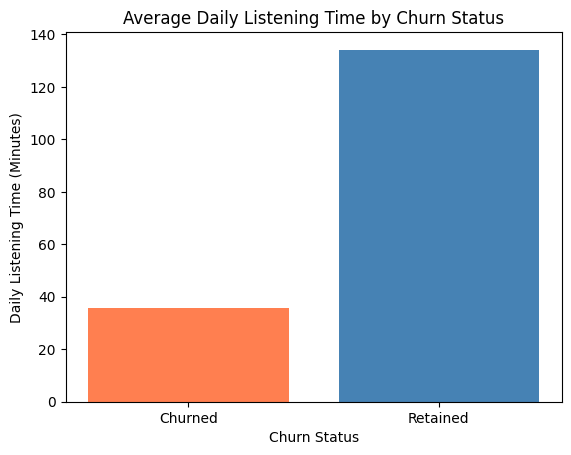

In [5]:
# 04. Average Daily Listening Time by Churn Status

df["churn_status"] = df["churned"].map({0: "Retained", 1: "Churned"})

listening_time = df.groupby("churn_status")["daily_minutes"].mean()

plt.bar(listening_time.index, listening_time.values, color=["coral", "steelblue"])
plt.title("Average Daily Listening Time by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Daily Listening Time (Minutes)")
plt.show()

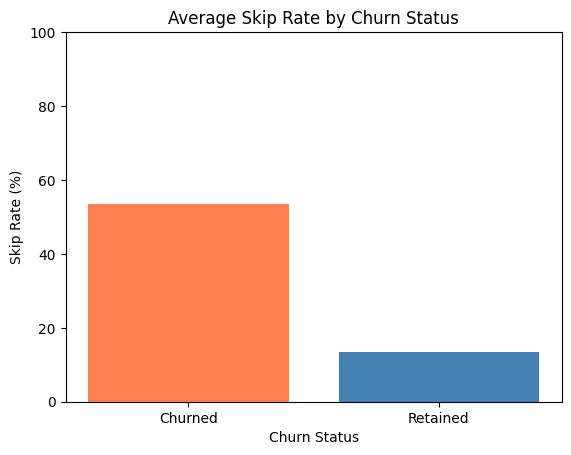

In [6]:
# 05. Average Skip Rate by Churn Status

skip_rate = df.groupby("churn_status")["skip_rate"].mean() * 100

plt.bar(skip_rate.index, skip_rate.values, color=["coral", "steelblue"])
plt.title("Average Skip Rate by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Skip Rate (%)")
plt.ylim(0, 100)
plt.show()

## Key Findings

- The overall churn rate was 44.29%, highlighting the importance of customer retention.
- Free users had a substantially higher churn rate than premium users (85.71% vs. 2.86%).
- Users aged 19–29 had the highest churn rate (82.35%).
- Churned users had approximately 73.5% lower average daily listening time than retained users.
- Churned users had a higher average skip rate than retained users (53.4% vs. 13.6%).

## Business Recommendations

- Prioritize free users and younger customer segments in retention initiatives.
- Monitor low listening time and high skip rates as potential indicators of customer disengagement.
- Test personalized music recommendations and targeted engagement campaigns to support customer retention.

## Conclusion

The analysis identified customer segments with higher churn rates and engagement patterns associated with churn. These findings can support data-driven decisions regarding customer retention strategies.

## Limitations

- The analysis is based on a small dataset of 70 users.
- Two missing skip rate values were excluded from the average skip rate calculations.
- The findings identify associations rather than causal relationships.